In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from wordcloud import WordCloud
import re
import nltk
from nltk.corpus import stopwords
from nltk.stem import PorterStemmer
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.metrics import confusion_matrix, classification_report, roc_curve, auc
from sklearn.model_selection import train_test_split


In [4]:
df = pd.read_csv("spam.csv", encoding="latin-1")
df = df[["v1", "v2"]].rename(columns={'v1':"label", 'v2':"text"})
df.head()

,label,text
0,ham,"Go until jurong point, crazy.. Available only ..."
1,ham,Ok lar... Joking wif u oni...
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...
3,ham,U dun say so early hor... U c already then say...
4,ham,"Nah I don't think he goes to usf, he lives aro..."


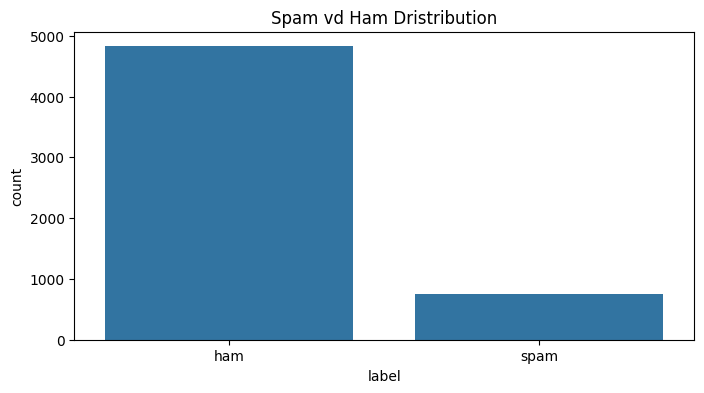

In [5]:
plt.figure(figsize=(8,4))
sns.countplot(data=df, x="label")
plt.title("Spam vd Ham Dristribution")
plt.show()

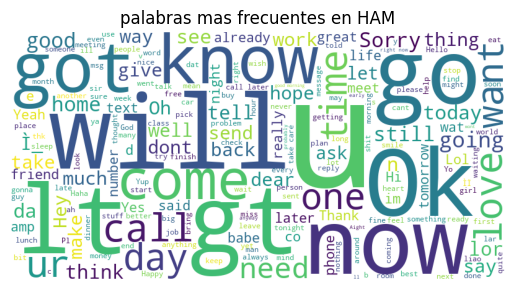

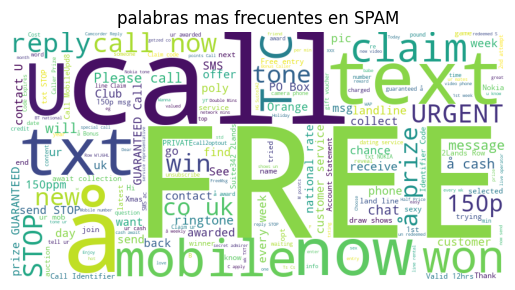

In [6]:
def plot_wordcloud(text,title):
    wordcloud = WordCloud(width=800, height=400, background_color="white").generate(text)
    plt.Figure(figsize=(10,5))
    plt.imshow(wordcloud)
    plt.title(title)
    plt.axis("off")
    plt.show()

ham_text = " ".join(df[df["label"] == "ham"] ["text"])
spam_text = " ".join(df[df["label"] == "spam"] ["text"])
plot_wordcloud(ham_text, "palabras mas frecuentes en HAM")
plot_wordcloud(spam_text, "palabras mas frecuentes en SPAM")

In [7]:
#Limpiar codigo 
nltk.download("stopwords")
stemmer = PorterStemmer()
stop_words= set(stopwords.words("english"))

def clean_text(text):
    text = text.lower()
    text = re.sub(r'[^a-zA-Z]', ' ',text)
    text = re.sub(r'\s+', ' ',text).strip()
    words = text.split()
    words = [stemmer.stem(word) for word in words if word not in stop_words]
    return " ".join(words) 

df["cleaned_text"] = df["text"].apply(clean_text)
df.head()


[nltk_data] Downloading package stopwords to
[nltk_data]     C:\Users\XOCEA\AppData\Roaming\nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


,label,text,cleaned_text
0,ham,"Go until jurong point, crazy.. Available only ...",go jurong point crazi avail bugi n great world...
1,ham,Ok lar... Joking wif u oni...,ok lar joke wif u oni
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...,free entri wkli comp win fa cup final tkt st m...
3,ham,U dun say so early hor... U c already then say...,u dun say earli hor u c alreadi say
4,ham,"Nah I don't think he goes to usf, he lives aro...",nah think goe usf live around though


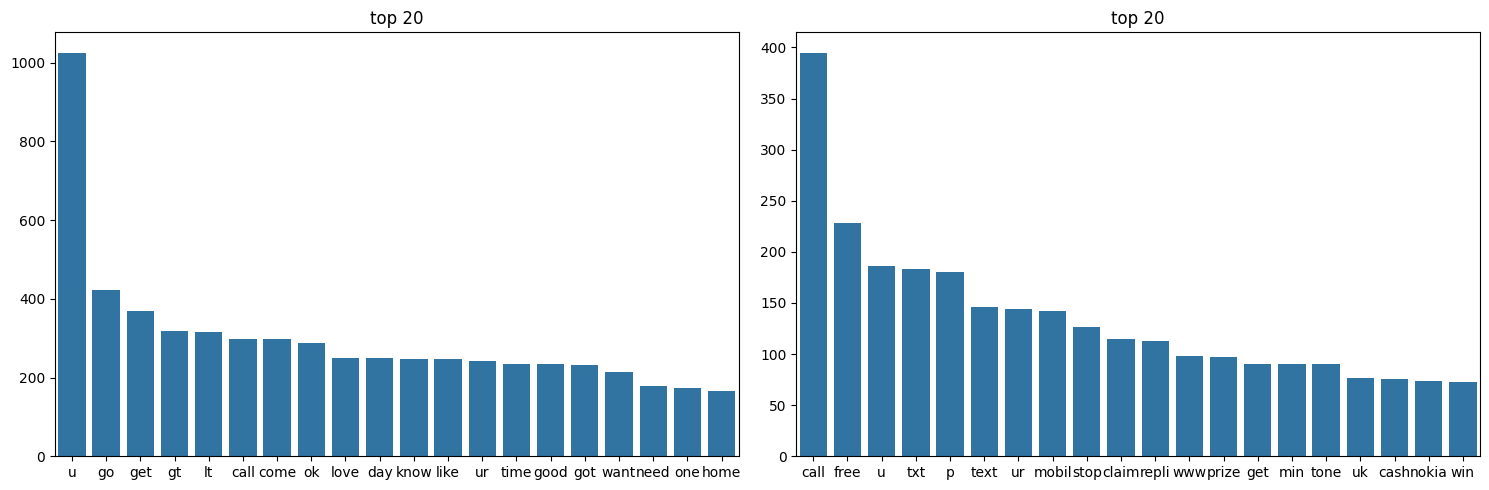

In [16]:
#Las palabras mas populares despues de la limpieza 
from collections import Counter
def get_top_words(text, n=20):
    all_words = " ".join(text).split()
    return Counter(all_words).most_common(n)

top_ham = get_top_words(df[df["label"] == "ham"]["cleaned_text"])
top_spam = get_top_words(df[df["label"] == "spam"]["cleaned_text"])

fig, axes = plt.subplots(1,2, figsize=(15,5))

sns.barplot(x=[word[0] for word in top_ham], y=[word[1] for word in top_ham], ax=axes[0])
axes[0].set_title("top 20")

sns.barplot(x=[word[0] for word in top_spam], y=[word[1] for word in top_spam], ax=axes[1])
axes[1].set_title("top 20")
plt.tight_layout()
plt.show()

In [17]:
#TF (term frequency) Que tan frecuente se repite una palabra 
#IDF (inverae doucument frecuency) Detecta palabras comunes 
#TF - IDF Vectorization
tfidf = TfidfVectorizer()
x = tfidf.fit_transform(df["cleaned_text"]).toarray()
y = df["label"].map({'ham':0, 'spam':1})

In [19]:
#Dividir la informacion
x_train, x_test, y_train, y_test = train_test_split(x,y, test_size=0.2, random_state=42)


In [20]:
#Naive Bayes
model = MultinomialNB()
model.fit(x_train,y_train)
y_pred = model.predict(x_test)

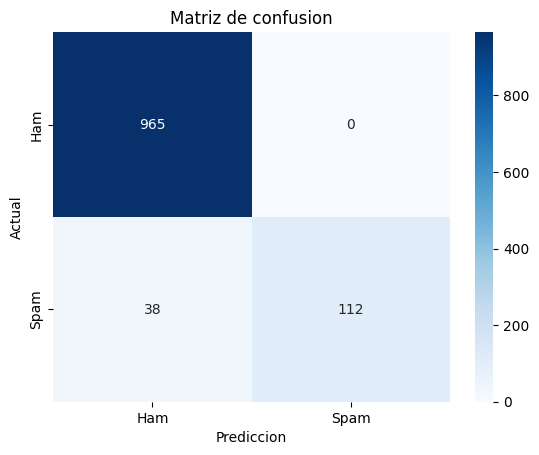

              precision    recall  f1-score   support

           0       0.96      1.00      0.98       965
           1       1.00      0.75      0.85       150

    accuracy                           0.97      1115
   macro avg       0.98      0.87      0.92      1115
weighted avg       0.97      0.97      0.96      1115



In [25]:
#Evaluacion
cm = confusion_matrix(y_test,y_pred)
sns.heatmap(cm, annot=True, fmt="d", xticklabels=["Ham", "Spam"], yticklabels=["Ham", "Spam"], cmap="Blues")
plt.xlabel("Prediccion")
plt.ylabel("Actual")
plt.title("Matriz de confusion")
plt.show()

print(classification_report(y_test, y_pred))

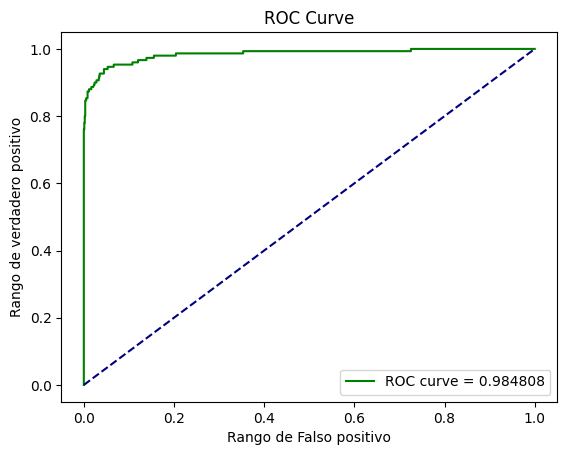

In [26]:
#Roc Curve 
y_prob = model.predict_proba(x_test)[:,1]
fpr, tpr, thresholds = roc_curve(y_test, y_prob)
roc_auc = auc(fpr, tpr)

plt.Figure(figsize=(8,6))
plt.plot(fpr, tpr, color="green", label=f"ROC curve = {roc_auc:2f}")
plt.plot([0,1],[0,1], color="navy", linestyle="--")
plt.xlabel("Rango de Falso positivo")
plt.ylabel("Rango de verdadero positivo")
plt.title("ROC Curve")
plt.legend()
plt.show()